# Part A — Data preprocessing and exploratory data analysis
**CDS3004 Data Mining | League of Legends Diamond Ranked Games (10 min)**

**Research question:** Can we predict the winning team using only statistics available after the first 10 minutes?

This is binary classification: `blueWins = 1` means Blue eventually wins; `blueWins = 0` means Red eventually wins. All candidate predictors describe the 10-minute snapshot. A predictive early statistic is not leakage merely because it has a strong association with the final result.

We use only the original [Kaggle dataset by bobbyscience](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min), `high_diamond_ranked_10min.csv`. No additional datasets or research questions are included. The source link documents provenance; the local CSV supplies every result below. The CSV alone cannot independently verify the publisher's extraction procedure or the timestamp of every measurement.

**Boundary of Part A:** validate and describe the source, reserve the test set, explore training data, and expose a reusable unscaled split. No models, tuning, model evaluation, scaling, imputation, or supervised feature selection are performed.


## 1. Reproduction and environment
Run all cells in order with the repository's `.venv` interpreter. Alternatively, from the repository root run `.venv/bin/python scripts/execute_notebook.py`; this uses a temporary kernel and saves visible outputs here.

The module discovers the original CSV in `data/raw/` or a sibling folder whose name is `Local_Datasets` after trimming whitespace. You can instead pass an explicit path or set `LOL_DATA_PATH`. Multiple matches raise an error. The raw CSV remains local, outside Git in this workspace. A checksum prevents the Part B interface from silently accepting a different source version.


In [1]:
import os
from pathlib import Path
import sys

# Support opening this notebook from either the root or notebooks/ folder.
working_directory = Path.cwd().resolve()
repository_candidates = [working_directory, *working_directory.parents]
repository_root = next(
    (folder for folder in repository_candidates
     if (folder / "src/lol_preprocessing.py").is_file()), None
)
if repository_root is None:
    raise FileNotFoundError("Open the notebook within this project repository.")
if str(repository_root) not in sys.path:
    sys.path.insert(0, str(repository_root))

# Keep plotting and interactive-shell caches in an ignored local directory.
os.environ.setdefault("MPLCONFIGDIR", str(repository_root / ".cache/matplotlib"))
os.environ.setdefault("IPYTHONDIR", str(repository_root / ".cache/ipython"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
Path(os.environ["IPYTHONDIR"]).mkdir(parents=True, exist_ok=True)

import importlib.metadata
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import Markdown, display
from src.lol_preprocessing import (
    BINARY_COLUMNS, DIFFERENCE_SOURCES, FEATURE_NAMES, ORIGINAL_SHA256,
    RANDOM_STATE, TARGET, audit_data, create_train_test_split,
    feature_decisions, load_data, prepare_data, prepare_features,
    resolve_data_path, save_split_manifest,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_columns", 45)
figure_directory = repository_root / "reports/figures"
figure_directory.mkdir(parents=True, exist_ok=True)

# Store metadata to check that every saved figure has titles and axis labels.
figure_records = []
def save_figure(figure, filename):
    for axis in figure.axes:
        if axis.get_visible():
            if axis.get_label() == "<colorbar>":
                assert axis.get_ylabel()
            else:
                assert axis.get_title() and axis.get_xlabel() and axis.get_ylabel()
    figure.savefig(figure_directory / filename, dpi=150, bbox_inches="tight")
    figure_records.append({"filename": filename, "axes": len(figure.axes)})
    plt.show()
    plt.close(figure)

print("Repository:", repository_root)
print("Python:", platform.python_version(), sys.executable)
packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "nbformat", "nbclient", "ipykernel"]
display(pd.Series({name: importlib.metadata.version(name) for name in packages}, name="version").to_frame())


Repository: <LOCAL_PROJECT_PARENT>/Predicting-League-of-Legends-match
Python: 3.11.5 <LOCAL_PROJECT_PARENT>/Predicting-League-of-Legends-match/.venv/bin/python


,version
numpy,2.1.3
pandas,2.2.3
matplotlib,3.9.2
seaborn,0.13.2
scikit-learn,1.5.2
nbformat,5.10.4
nbclient,0.10.0
ipykernel,6.29.5


## 2. Initial inspection — purely descriptive, all source records
The checks in Sections 2–3 describe the original file and verify data integrity. They do not rank predictors or learn transformations. We display the requested full-source summary statistics, but do not use them to choose distribution-based preprocessing. All predictor/outcome plots and outlier investigations after reserving the test set use training data only.


In [2]:
source_path = resolve_data_path()
raw_data = load_data(source_path)
print("CSV:", source_path)
print("CSV outside repository:", not source_path.is_relative_to(repository_root))
print(f"Verified dimensions: {raw_data.shape[0]:,} matches × {raw_data.shape[1]} columns")
print("Target: blueWins = 1 → Blue wins; blueWins = 0 → Red wins")
display(raw_data.head(5))


CSV: <LOCAL_PROJECT_PARENT>/Local_Datasets /high_diamond_ranked_10min.csv
CSV outside repository: True
Verified dimensions: 9,879 matches × 40 columns
Target: blueWins = 1 → Blue wins; blueWins = 0 → Red wins


,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,blueHeralds,blueTowersDestroyed,blueTotalGold,blueAvgLevel,blueTotalExperience,blueTotalMinionsKilled,blueTotalJungleMinionsKilled,blueGoldDiff,blueExperienceDiff,blueCSPerMin,blueGoldPerMin,redWardsPlaced,redWardsDestroyed,redFirstBlood,redKills,redDeaths,redAssists,redEliteMonsters,redDragons,redHeralds,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,0,0,17210,6.6,17039,195,36,643,-8,19.5,1721.0,15,6,0,6,9,8,0,0,0,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,0,0,14712,6.6,16265,174,43,-2908,-1173,17.4,1471.2,12,1,1,5,5,2,2,1,1,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,0,0,16113,6.4,16221,186,46,-1172,-1033,18.6,1611.3,15,3,1,11,7,14,0,0,0,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,1,0,15157,7.0,17954,201,55,-1321,-7,20.1,1515.7,15,2,1,5,4,10,0,0,0,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,0,0,16400,7.0,18543,210,57,-1004,230,21.0,1640.0,17,2,1,6,6,7,1,1,0,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


In [3]:
print("Column names:")
for number, column in enumerate(raw_data.columns, start=1):
    print(f"{number:2}. {column}")
print("\nData types and non-null counts:")
raw_data.info()
display(raw_data.dtypes.astype(str).rename("dtype").to_frame())


Column names:
 1. gameId
 2. blueWins
 3. blueWardsPlaced
 4. blueWardsDestroyed
 5. blueFirstBlood
 6. blueKills
 7. blueDeaths
 8. blueAssists
 9. blueEliteMonsters
10. blueDragons
11. blueHeralds
12. blueTowersDestroyed
13. blueTotalGold
14. blueAvgLevel
15. blueTotalExperience
16. blueTotalMinionsKilled
17. blueTotalJungleMinionsKilled
18. blueGoldDiff
19. blueExperienceDiff
20. blueCSPerMin
21. blueGoldPerMin
22. redWardsPlaced
23. redWardsDestroyed
24. redFirstBlood
25. redKills
26. redDeaths
27. redAssists
28. redEliteMonsters
29. redDragons
30. redHeralds
31. redTowersDestroyed
32. redTotalGold
33. redAvgLevel
34. redTotalExperience
35. redTotalMinionsKilled
36. redTotalJungleMinionsKilled
37. redGoldDiff
38. redExperienceDiff
39. redCSPerMin
40. redGoldPerMin

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9879 entries, 0 to 9878
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------           

,dtype
gameId,int64
blueWins,int64
blueWardsPlaced,int64
blueWardsDestroyed,int64
blueFirstBlood,int64
blueKills,int64
blueDeaths,int64
blueAssists,int64
blueEliteMonsters,int64
blueDragons,int64


In [4]:
# Transposing describe() keeps all 40 columns readable as rows.
display(raw_data.describe().T.round(2))
low_cardinality_columns = list(BINARY_COLUMNS) + [
    "blueEliteMonsters", "redEliteMonsters", "blueTowersDestroyed", "redTowersDestroyed"
]
cardinality = pd.DataFrame({
    "unique_values": raw_data[low_cardinality_columns].nunique(),
    "observed_values": [sorted(raw_data[column].unique().tolist()) for column in low_cardinality_columns],
})
display(cardinality)
print("All source columns are numeric; low-cardinality numerical columns encode flags or counts, not text categories.")


,count,mean,std,min,25%,50%,75%,max
gameId,9879.0,4.500084e+09,27573278.49,4.295358e+09,4.483301e+09,4.510920e+09,4.521733e+09,4.527991e+09
blueWins,9879.0,5.000000e-01,0.50,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
blueWardsPlaced,9879.0,2.229000e+01,18.02,5.000000e+00,1.400000e+01,1.600000e+01,2.000000e+01,2.500000e+02
blueWardsDestroyed,9879.0,2.820000e+00,2.17,0.000000e+00,1.000000e+00,3.000000e+00,4.000000e+00,2.700000e+01
blueFirstBlood,9879.0,5.000000e-01,0.50,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
blueKills,9879.0,6.180000e+00,3.01,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueDeaths,9879.0,6.140000e+00,2.93,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueAssists,9879.0,6.650000e+00,4.06,0.000000e+00,4.000000e+00,6.000000e+00,9.000000e+00,2.900000e+01
blueEliteMonsters,9879.0,5.500000e-01,0.63,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00
blueDragons,9879.0,3.600000e-01,0.48,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


,unique_values,observed_values
blueWins,2,"[0, 1]"
blueFirstBlood,2,"[0, 1]"
redFirstBlood,2,"[0, 1]"
blueDragons,2,"[0, 1]"
redDragons,2,"[0, 1]"
blueHeralds,2,"[0, 1]"
redHeralds,2,"[0, 1]"
blueEliteMonsters,3,"[0, 1, 2]"
redEliteMonsters,3,"[0, 1, 2]"
blueTowersDestroyed,5,"[0, 1, 2, 3, 4]"


All source columns are numeric; low-cardinality numerical columns encode flags or counts, not text categories.


## 3. Systematic data quality assessment — all source records
### 3.1 Missing values and duplicate records
An identical row repeats **every** stored value. A repeated `gameId` means the same match appears again, possibly with conflicting statistics or outcomes. These are separate checks. We investigate and stop on either issue; we never quietly remove rows. Missing or invalid data also cause a visible validation error. If a future source version has missing predictors, establish why they are missing first; learned imputation would belong inside training-fold pipelines.


In [5]:
quality_report = audit_data(raw_data)
missing_table = quality_report["missing_by_column"].rename("missing_count").to_frame()
missing_table["missing_percent"] = missing_table["missing_count"] / len(raw_data) * 100
display(missing_table)
print("Total missing values:", quality_report["total_missing"])
print("Completely duplicated rows:", quality_report["duplicate_rows"])
print("Repeated gameId values (after first occurrence):", quality_report["duplicate_game_ids"])
print("gameId uniquely identifies matches:", raw_data.gameId.is_unique)
print("Validation issues:", quality_report["errors"])
assert quality_report["errors"] == []


,missing_count,missing_percent
gameId,0,0.0
blueWins,0,0.0
blueWardsPlaced,0,0.0
blueWardsDestroyed,0,0.0
blueFirstBlood,0,0.0
blueKills,0,0.0
blueDeaths,0,0.0
blueAssists,0,0.0
blueEliteMonsters,0,0.0
blueDragons,0,0.0


Total missing values: 0
Completely duplicated rows: 0
Repeated gameId values (after first occurrence): 0
gameId uniquely identifies matches: True
Validation issues: []


### 3.2 Types, valid values, and team consistency
We check numeric and finite values, binary flags in `{0, 1}`, integer count columns, nonnegative non-difference statistics, positive match IDs, and average champion levels in `[1, 18]`. Negative **difference** values are valid Red leads and must remain negative. The level bounds are basic domain limits, not fitted thresholds or outlier removal rules.

We also verify arithmetic identities directly. Gold/minute and CS/minute are exact rescalings at the common ten-minute snapshot. `CSPerMin` here equals lane minions / 10; it does not add jungle minions. Elite monsters equal dragons plus heralds in this file. First-blood flags sum to one in every supplied row. A changed file that violates these verified source contracts requires investigation rather than arbitrary correction.


In [6]:
display(quality_report["validity"])
display(quality_report["relationships"])
assert quality_report["validity"].to_numpy().sum() == 0
assert quality_report["relationships"]["violations"].sum() == 0
print("No rows or values were altered. Final observation count:", len(raw_data))


,negative_non_difference,invalid_binary,fractional_count,invalid_level,invalid_id
column,,,,,
gameId,0,0,0,0,0
blueWins,0,0,0,0,0
blueWardsPlaced,0,0,0,0,0
blueWardsDestroyed,0,0,0,0,0
blueFirstBlood,0,0,0,0,0
blueKills,0,0,0,0,0
blueDeaths,0,0,0,0,0
blueAssists,0,0,0,0,0
blueEliteMonsters,0,0,0,0,0


,violations,maximum_absolute_error
relationship,,
blueKills = redDeaths,0,0.0
redKills = blueDeaths,0,0.0
first-blood flags sum to 1,0,0.0
blueGoldDiff = blueTotalGold - redTotalGold,0,0.0
redGoldDiff = -blueGoldDiff,0,0.0
blueExperienceDiff = blueTotalExperience - redTotalExperience,0,0.0
redExperienceDiff = -blueExperienceDiff,0,0.0
blueGoldPerMin = blueTotalGold / 10,0,0.0
blueCSPerMin = blueTotalMinionsKilled / 10,0,0.0


No rows or values were altered. Final observation count: 9879


## 4. Fixed feature policy — specified without target associations
We retain **12 relative-advantage predictors**, all available at the ten-minute snapshot. Positive values favor Blue; negative values favor Red. Two existing Blue differences are reused; ten differences are calculated as `Blue − Red` with no fitted parameters.

This is **domain-based dimensionality reduction**, not supervised feature selection. We verify known mathematical relationships during the source audit; we do not choose columns by looking at held-out associations or distributions. `gameId` is only an index and a deterministic sorting key; it is never a predictor. `blueWins` is only the response.

The design intentionally omits absolute game tempo. Equal leads can occur at different absolute gold or kill totals, and an objective difference of zero can merge distinct tied states. Average level is a coarse experience-related summary, **not** a verified exact duplicate. Omitting it is an explicit simplicity tradeoff. This is an explainable baseline representation, not a claim that all excluded variables lack predictive value. Any future comparison of representations must use training cross-validation.


In [7]:
print("Retained original predictors:", list(FEATURE_NAMES[:2]))
engineered_features = pd.DataFrame([
    {"feature": name, "formula": f"blue{statistic} - red{statistic}"}
    for name, statistic in DIFFERENCE_SOURCES.items()
])
display(engineered_features)
# Each original column has an explicit action and reason.
display(feature_decisions())
assert len(feature_decisions()) == raw_data.shape[1]
assert {TARGET, "gameId"}.isdisjoint(FEATURE_NAMES)


Retained original predictors: ['blueGoldDiff', 'blueExperienceDiff']


,feature,formula
0,killsDiff,blueKills - redKills
1,assistsDiff,blueAssists - redAssists
2,minionsDiff,blueTotalMinionsKilled - redTotalMinionsKilled
3,jungleMinionsDiff,blueTotalJungleMinionsKilled - redTotalJungleM...
4,wardsPlacedDiff,blueWardsPlaced - redWardsPlaced
5,wardsDestroyedDiff,blueWardsDestroyed - redWardsDestroyed
6,firstBloodDiff,blueFirstBlood - redFirstBlood
7,dragonsDiff,blueDragons - redDragons
8,heraldsDiff,blueHeralds - redHeralds
9,towersDestroyedDiff,blueTowersDestroyed - redTowersDestroyed


,original_column,decision,reason
0,gameId,Exclude from X,Match identifier; used only as a row index and...
1,blueWins,Target only,Final result; never a predictor.
2,blueWardsPlaced,Replace by difference,Contributes to wardsPlacedDiff = Blue - Red; a...
3,blueWardsDestroyed,Replace by difference,Contributes to wardsDestroyedDiff = Blue - Red...
4,blueFirstBlood,Replace by difference,Contributes to firstBloodDiff = Blue - Red; ab...
5,blueKills,Replace by difference,Contributes to killsDiff = Blue - Red; absolut...
6,blueDeaths,Exclude,Exact copy of opposing kills (verified); kills...
7,blueAssists,Replace by difference,Contributes to assistsDiff = Blue - Red; absol...
8,blueEliteMonsters,Exclude,Exactly Dragons + Heralds (verified); retain t...
9,blueDragons,Replace by difference,Contributes to dragonsDiff = Blue - Red; absol...


## 5. Reserve the test set before model-development EDA
Use 80% training and 20% test data, `stratify=y`, and `random_state=42`. The module first sorts by unique `gameId`, so CSV row reordering cannot change split membership. Sorting is not chronological splitting: match IDs are not treated as reliable timestamps. The design is a stratified random holdout for this supplied sample, not a claim about future-patch generalization.

`prepare_data()` verifies the original file checksum and applies the fixed feature policy. No values are scaled, imputed, clipped, or fitted. A local ignored manifest records the checksum, feature order, and train/test match IDs **without storing labels or predictor values**. It refuses to overwrite a different split silently.


In [8]:
prepared = prepare_data(source_path)
X_train, X_test = prepared.X_train, prepared.X_test
y_train, y_test = prepared.y_train, prepared.y_test
manifest_path = save_split_manifest(prepared)
print("Original CSV SHA-256:", prepared.source_sha256)
print("Local ignored split manifest:", manifest_path.relative_to(repository_root))

split_rows = []
for name, predictors, target in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
    counts = target.value_counts().reindex([0, 1], fill_value=0)
    split_rows.append({
        "set": name, "rows": len(predictors), "predictors": predictors.shape[1],
        "Red wins (0)": int(counts[0]), "Blue wins (1)": int(counts[1]),
        "Red %": counts[0] / len(target) * 100, "Blue %": counts[1] / len(target) * 100,
    })
split_summary = pd.DataFrame(split_rows).set_index("set")
display(split_summary.round(3))
print("X_train", X_train.shape, "X_test", X_test.shape)
print("y_train", y_train.shape, "y_test", y_test.shape)
# Only these training records are used for all subsequent development EDA.
training_raw = raw_data.set_index("gameId").loc[X_train.index].copy()
training_eda = X_train.join(y_train)


Original CSV SHA-256: 82b2e23279097c2dac616e966eb2911711c428d41b6382b4cdb15da4892f9ca6
Local ignored split manifest: data/processed/split_manifest.json


,rows,predictors,Red wins (0),Blue wins (1),Red %,Blue %
set,,,,,,
Training,7903,12,3959,3944,50.095,49.905
Test,1976,12,990,986,50.101,49.899


X_train (7903, 12) X_test (1976, 12)
y_train (7903,) y_test (1976,)


## 6. Target distribution — descriptive class counts
Full-source class counts are shown because class balance is a basic dataset description; this is the only full-source figure. Train/test class counts above are partition diagnostics. No predictor–target relationship uses the test set. Blue and Red wins are almost equally frequent, so there is no evident class-count reason to introduce resampling. Class balance alone does not establish that the problem is easy or representative of all League matches.


,winner,matches,percent
0,Red (0),4949,50.096
1,Blue (1),4930,49.904


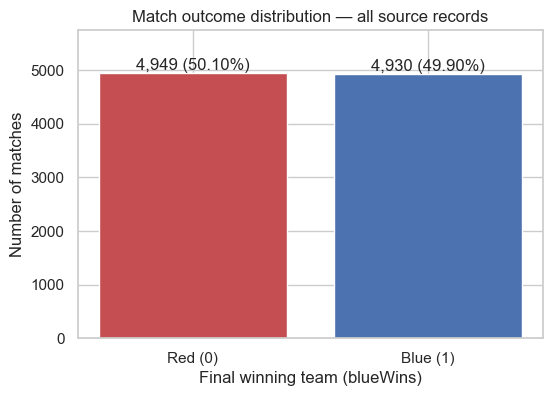

In [9]:
class_counts = raw_data[TARGET].value_counts().reindex([0, 1], fill_value=0)
class_distribution = pd.DataFrame({
    "winner": ["Red (0)", "Blue (1)"], "matches": class_counts.to_numpy(),
    "percent": class_counts.to_numpy() / len(raw_data) * 100,
})
display(class_distribution.round(3))
figure, axis = plt.subplots(figsize=(6, 4))
bars = axis.bar(class_distribution.winner, class_distribution.matches, color=["#c44e52", "#4c72b0"])
axis.set(title="Match outcome distribution — all source records", xlabel="Final winning team (blueWins)", ylabel="Number of matches")
axis.set_ylim(0, class_distribution.matches.max() * 1.16)
for bar, count, percent in zip(bars, class_distribution.matches, class_distribution.percent):
    axis.text(bar.get_x() + bar.get_width()/2, count + 50, f"{count:,} ({percent:.2f}%)", ha="center")
save_figure(figure, "01_target_class_distribution.png")


## 7. Unusual values and outliers — training data only
We inspect gold, kills, experience, lane/jungle minions, and wards for **both teams**. IQR flags (`Q1 − 1.5 IQR`, `Q3 + 1.5 IQR`) are descriptive labels, not gameplay-validity limits. They are calculated from training data only and never used to discard or cap values. Boxplot markers show these same kinds of unusual observations.


,count,mean,std,min,1%,25%,50%,75%,99%,max,IQR_flagged_count,IQR_flagged_percent
blueTotalGold,7903.0,16504.87,1537.61,10730.0,13449.00,15412.0,16402.0,17466.5,20603.98,23701.0,87,1.10
redTotalGold,7903.0,16482.42,1491.13,11212.0,13500.02,15420.5,16368.0,17414.5,20345.92,22732.0,76,0.96
blueKills,7903.0,6.19,3.00,0.0,1.00,4.0,6.0,8.0,14.00,19.0,68,0.86
redKills,7903.0,6.14,2.93,0.0,1.00,4.0,6.0,8.0,14.00,22.0,53,0.67
blueTotalExperience,7903.0,17926.30,1208.05,10098.0,14965.42,17162.5,17954.0,18719.0,20646.90,22224.0,91,1.15
redTotalExperience,7903.0,17952.43,1199.19,10465.0,14862.02,17196.5,17961.0,18745.0,20573.00,22269.0,111,1.40
blueTotalMinionsKilled,7903.0,216.50,21.94,90.0,161.00,202.0,218.0,232.0,263.00,283.0,54,0.68
redTotalMinionsKilled,7903.0,217.18,21.86,107.0,163.00,203.0,218.0,232.0,264.00,289.0,72,0.91
blueTotalJungleMinionsKilled,7903.0,50.49,9.92,0.0,28.00,44.0,50.0,56.0,75.00,92.0,134,1.70
redTotalJungleMinionsKilled,7903.0,51.28,10.00,4.0,29.00,44.0,51.0,57.0,76.00,92.0,102,1.29


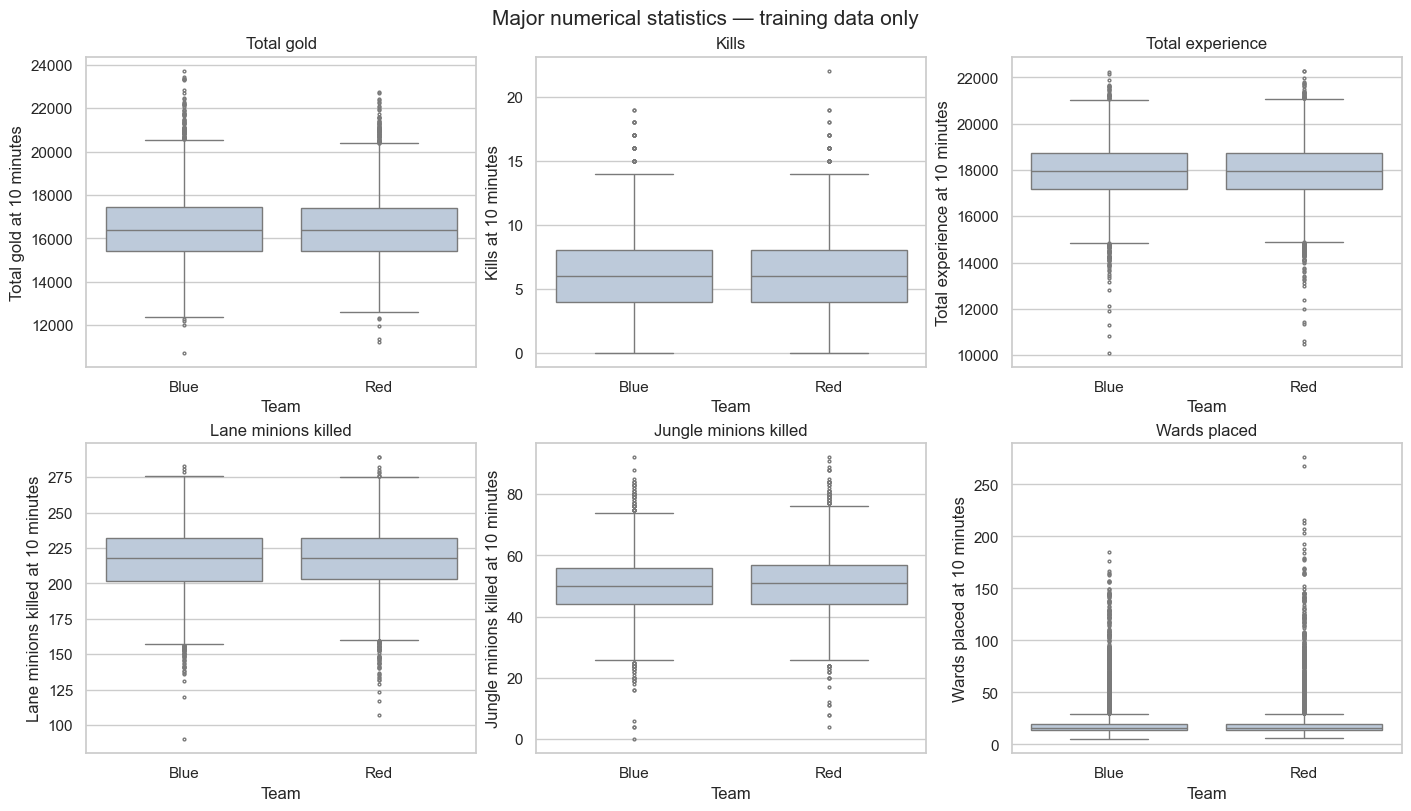

In [10]:
major_statistics = {
    "TotalGold": "Total gold", "Kills": "Kills", "TotalExperience": "Total experience",
    "TotalMinionsKilled": "Lane minions killed", "TotalJungleMinionsKilled": "Jungle minions killed",
    "WardsPlaced": "Wards placed",
}
major_columns = [team + statistic for statistic in major_statistics for team in ["blue", "red"]]
outlier_summary = training_raw[major_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
quartile_one = training_raw[major_columns].quantile(.25)
quartile_three = training_raw[major_columns].quantile(.75)
interquartile_range = quartile_three - quartile_one
flags = (training_raw[major_columns] < quartile_one - 1.5 * interquartile_range) | (training_raw[major_columns] > quartile_three + 1.5 * interquartile_range)
outlier_summary["IQR_flagged_count"] = flags.sum()
outlier_summary["IQR_flagged_percent"] = flags.mean() * 100
display(outlier_summary.round(2))

figure, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for axis, (statistic, label) in zip(axes.flat, major_statistics.items()):
    columns = ["blue" + statistic, "red" + statistic]
    long_values = training_raw[columns].rename(columns={columns[0]: "Blue", columns[1]: "Red"}).melt(var_name="Team", value_name=label)
    sns.boxplot(data=long_values, x="Team", y=label, color="#b8c9df", fliersize=2, ax=axis)
    axis.set(title=label, xlabel="Team", ylabel=label + " at 10 minutes")
figure.suptitle("Major numerical statistics — training data only", fontsize=15)
save_figure(figure, "02_training_major_statistics_boxplots.png")


In [11]:
# Investigate unusually large ward counts without inspecting any final outcomes.
ward_extremes = training_raw[["blueWardsPlaced", "redWardsPlaced"]].max(axis=1).nlargest(5).index
display(training_raw.loc[ward_extremes, ["blueWardsPlaced", "redWardsPlaced", "blueKills", "redKills", "blueTotalGold", "redTotalGold"]])
ward_maximum = int(training_raw[["blueWardsPlaced", "redWardsPlaced"]].max().max())
display(Markdown(
    f"Training ward counts reach **{ward_maximum}** for one team in ten minutes. "
    "Hundreds of wards are especially suspicious and could reflect recording or extraction artifacts; "
    "the CSV cannot confirm their cause. We flag this uncertainty and retain the observations. "
    "Large gold, combat, experience, and minion values can reflect unusually one-sided or active games; "
    "an IQR flag alone does not make them invalid. No extreme value is removed, capped, or replaced. "
    "If Part B investigates robust preprocessing, its rules and any choice must be fitted and assessed "
    "using training cross-validation only."
))


,blueWardsPlaced,redWardsPlaced,blueKills,redKills,blueTotalGold,redTotalGold
gameId,,,,,,
4495729689,16,276,5,8,15967,17545
4506217760,14,268,11,6,18056,17806
4462493939,16,216,8,9,16984,18704
4514331863,16,213,16,7,20300,16991
4474929449,18,207,5,5,16947,15967


Training ward counts reach **276** for one team in ten minutes. Hundreds of wards are especially suspicious and could reflect recording or extraction artifacts; the CSV cannot confirm their cause. We flag this uncertainty and retain the observations. Large gold, combat, experience, and minion values can reflect unusually one-sided or active games; an IQR flag alone does not make them invalid. No extreme value is removed, capped, or replaced. If Part B investigates robust preprocessing, its rules and any choice must be fitted and assessed using training cross-validation only.

## 8. Early-game feature distributions — training data only
Continuous and count differences share a common interpretation: Blue minus Red. We show a small set of informative distributions rather than repeating all raw team columns. The zero reference line marks equal statistics. Objective and first-blood differences are discrete; they require count plots rather than continuous-density curves.


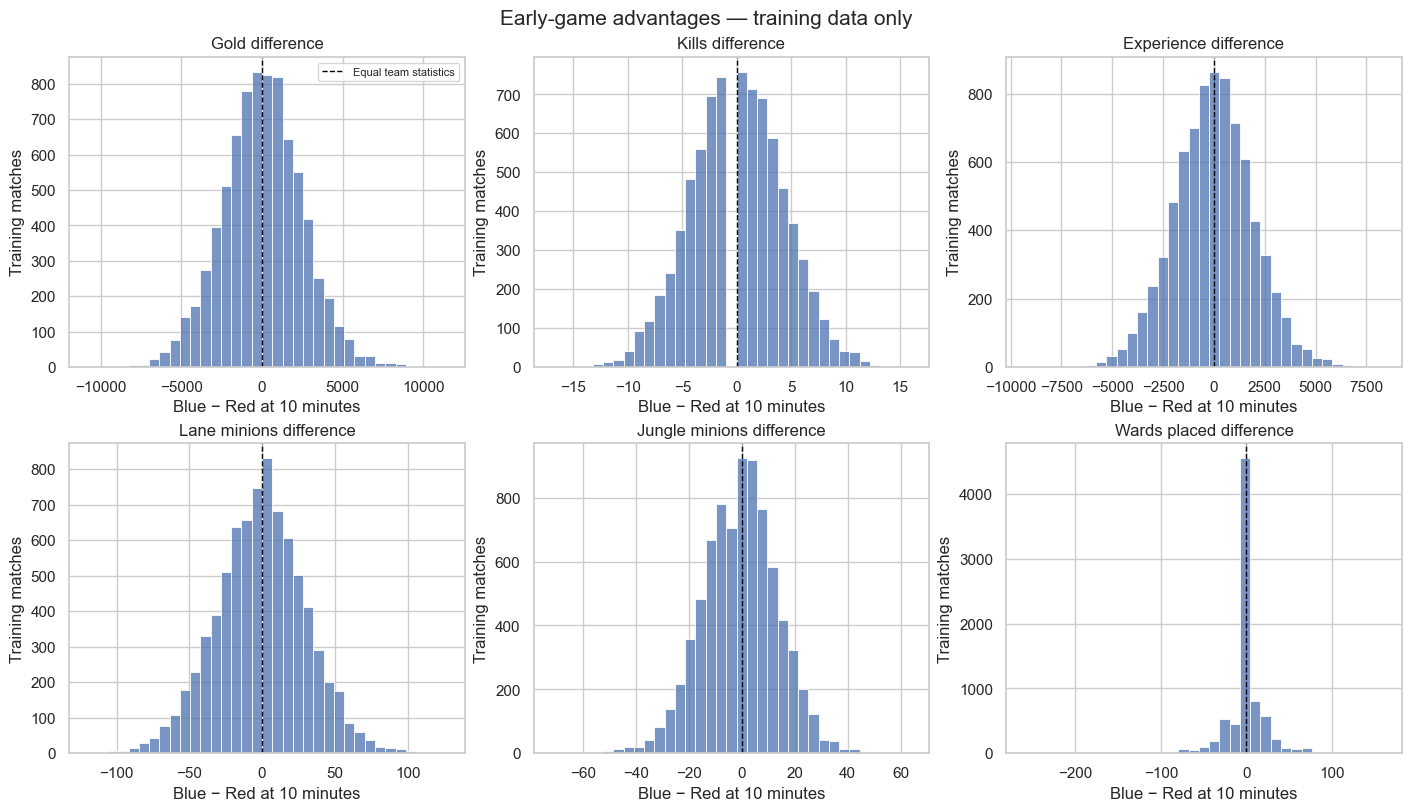

,mean,median,std,min,max
blueGoldDiff,22.46,26.0,2459.54,-10830.0,11467.0
killsDiff,0.06,0.0,4.20,-17.0,16.0
blueExperienceDiff,-26.14,-10.0,1927.80,-9333.0,8348.0
minionsDiff,-0.69,-1.0,30.94,-120.0,127.0
jungleMinionsDiff,-0.79,0.0,14.26,-72.0,64.0
wardsPlacedDiff,-0.19,0.0,25.77,-260.0,161.0


In [12]:
feature_labels = {
    "blueGoldDiff": "Gold difference", "blueExperienceDiff": "Experience difference",
    "killsDiff": "Kills difference", "assistsDiff": "Assists difference",
    "minionsDiff": "Lane minions difference", "jungleMinionsDiff": "Jungle minions difference",
    "wardsPlacedDiff": "Wards placed difference", "wardsDestroyedDiff": "Wards destroyed difference",
    "firstBloodDiff": "First-blood difference", "dragonsDiff": "Dragons difference",
    "heraldsDiff": "Heralds difference", "towersDestroyedDiff": "Towers destroyed difference",
}
continuous_features = ["blueGoldDiff", "killsDiff", "blueExperienceDiff", "minionsDiff", "jungleMinionsDiff", "wardsPlacedDiff"]
figure, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for axis, feature in zip(axes.flat, continuous_features):
    sns.histplot(X_train[feature], bins=35, color="#4c72b0", ax=axis)
    axis.axvline(0, color="black", linestyle="--", linewidth=1, label="Equal team statistics")
    axis.set(title=feature_labels[feature], xlabel="Blue − Red at 10 minutes", ylabel="Training matches")
axes.flat[0].legend(fontsize=8)
figure.suptitle("Early-game advantages — training data only", fontsize=15)
save_figure(figure, "03_training_feature_distributions.png")
display(X_train[continuous_features].agg(["mean", "median", "std", "min", "max"]).T.round(2))


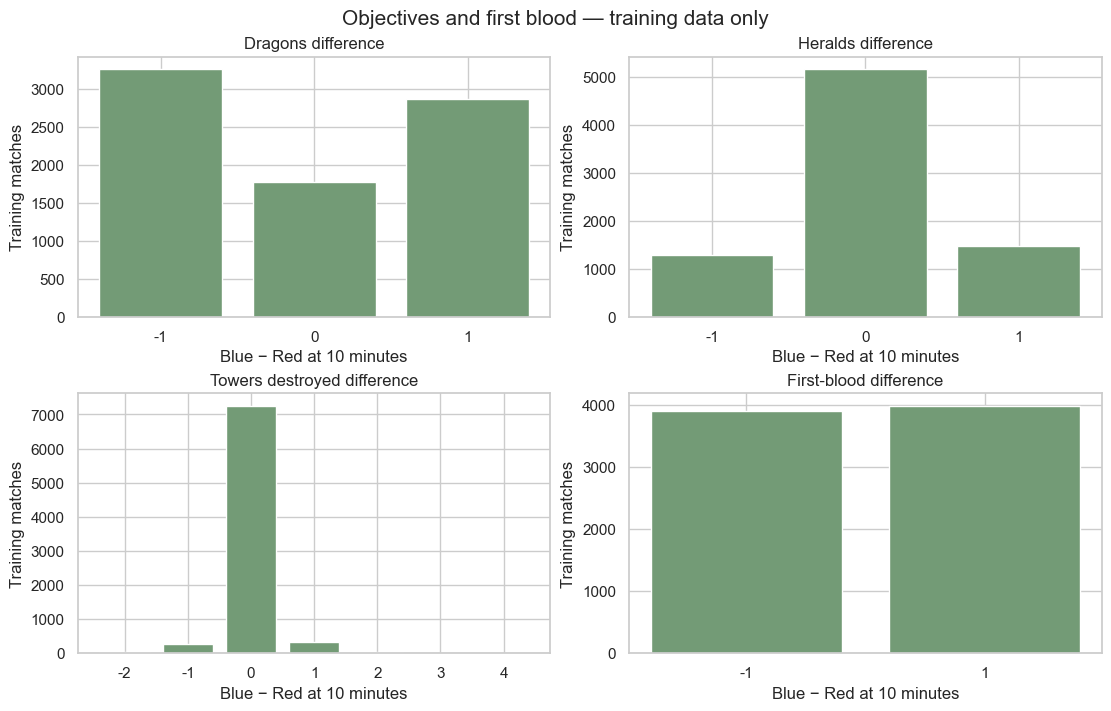

The printed medians describe typical leads; the tails show that some matches have much larger advantages. Dragon and herald differences use only a few integer values in this source. First blood has no zero category here because exactly one team has the first-blood flag. A zero objective difference means equal recorded totals, not necessarily that no objective was taken.

In [13]:
discrete_features = ["dragonsDiff", "heraldsDiff", "towersDestroyedDiff", "firstBloodDiff"]
figure, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for axis, feature in zip(axes.flat, discrete_features):
    counts = X_train[feature].value_counts().sort_index()
    axis.bar(counts.index.astype(str), counts.values, color="#739b76")
    axis.set(title=feature_labels[feature], xlabel="Blue − Red at 10 minutes", ylabel="Training matches")
figure.suptitle("Objectives and first blood — training data only", fontsize=15)
save_figure(figure, "04_training_objective_distributions.png")
display(Markdown(
    "The printed medians describe typical leads; the tails show that some matches have much larger advantages. "
    "Dragon and herald differences use only a few integer values in this source. "
    "First blood has no zero category here because exactly one team has the first-blood flag. "
    "A zero objective difference means equal recorded totals, not necessarily that no objective was taken."
))


## 9. Relationships with final outcomes — training data only
### 9.1 Gold and kill leads
We group leads using fixed, interpretable bin boundaries and calculate the observed fraction of Blue wins in each training group. Labels show sample counts, since a percentage based on a small group is less stable. These are descriptive conditional proportions, not predictions from a fitted model, and they establish association rather than causation. Many game variables influence one another.


,matches,blue_wins,blue_win_rate
group,,,
≤ −4000,416,20,0.048
−4000 to −2000,1150,188,0.163
−2000 to −1000,1075,320,0.298
−1000 to 0,1277,557,0.436
0 to 1000,1291,715,0.554
1000 to 2000,1089,748,0.687
2000 to 4000,1184,1000,0.845
> 4000,421,396,0.941


,matches,blue_wins,blue_win_rate
group,,,
≤ −6,718,65,0.091
−5 to −3,1394,337,0.242
−2 to −1,1440,568,0.394
0,758,385,0.508
1,714,396,0.555
2 to 3,1279,847,0.662
4 to 6,1106,888,0.803
≥ 7,494,458,0.927


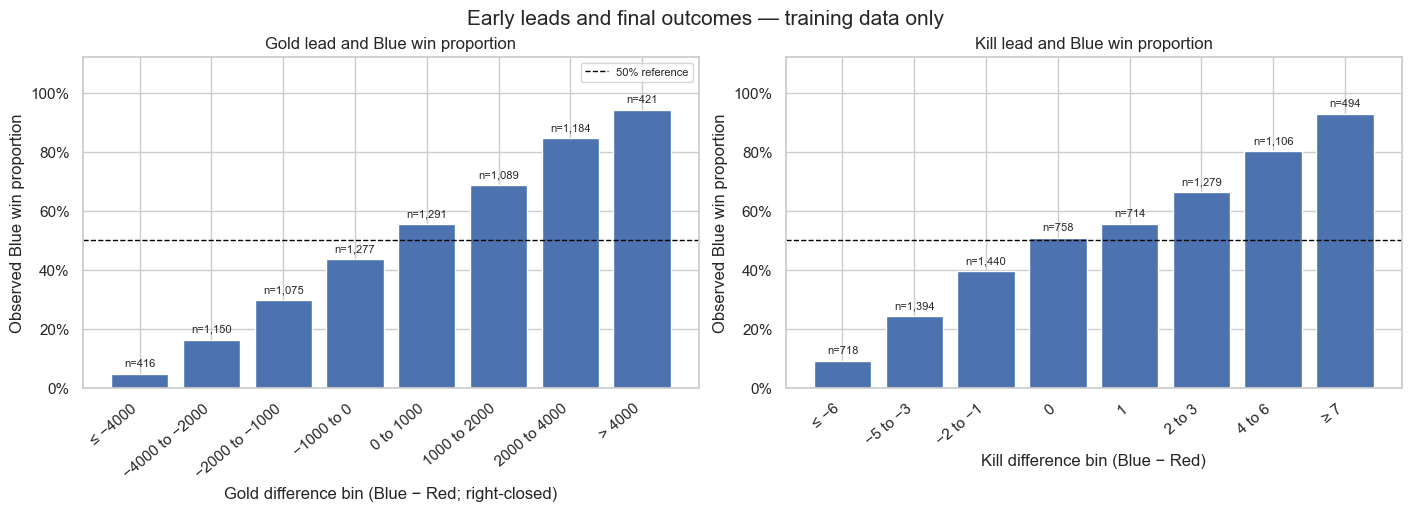

The lowest and highest gold-lead bins have observed Blue win proportions of **4.8%** and **94.1%**, respectively. For the extreme kill-lead bins they are **9.1%** and **92.7%**. These training summaries associate larger leads with victory; they do not demonstrate that changing a single statistic causes a win.

In [14]:
def outcome_by_group(groups):
    grouped = pd.DataFrame({"group": groups, TARGET: y_train}).groupby("group", observed=True)[TARGET]
    return grouped.agg(matches="size", blue_wins="sum", blue_win_rate="mean")

gold_bins = [-np.inf, -4000, -2000, -1000, 0, 1000, 2000, 4000, np.inf]
gold_labels = ["≤ −4000", "−4000 to −2000", "−2000 to −1000", "−1000 to 0", "0 to 1000", "1000 to 2000", "2000 to 4000", "> 4000"]
kill_bins = [-np.inf, -6, -3, -1, 0, 1, 3, 6, np.inf]
kill_labels = ["≤ −6", "−5 to −3", "−2 to −1", "0", "1", "2 to 3", "4 to 6", "≥ 7"]
# pd.cut intervals are right-closed: (lower, upper].
gold_groups = pd.cut(X_train.blueGoldDiff, bins=gold_bins, labels=gold_labels)
kill_groups = pd.cut(X_train.killsDiff, bins=kill_bins, labels=kill_labels)
gold_outcomes = outcome_by_group(gold_groups)
kill_outcomes = outcome_by_group(kill_groups)
display(gold_outcomes.round(3))
display(kill_outcomes.round(3))
figure, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for axis, table, title, xlabel in [
    (axes[0], gold_outcomes, "Gold lead and Blue win proportion", "Gold difference bin (Blue − Red; right-closed)"),
    (axes[1], kill_outcomes, "Kill lead and Blue win proportion", "Kill difference bin (Blue − Red)"),
]:
    positions = np.arange(len(table))
    axis.bar(positions, table.blue_win_rate, color="#4c72b0")
    axis.set_xticks(positions, table.index.astype(str), rotation=40, ha="right")
    axis.axhline(.5, color="black", linestyle="--", linewidth=1, label="50% reference")
    for position, (_, row) in enumerate(table.iterrows()):
        axis.text(position, row.blue_win_rate + .025, f"n={int(row.matches):,}", ha="center", fontsize=8)
    axis.set(title=title, xlabel=xlabel, ylabel="Observed Blue win proportion", ylim=(0, 1.12))
    axis.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
figure.suptitle("Early leads and final outcomes — training data only", fontsize=15)
save_figure(figure, "05_training_win_proportions_gold_kills.png")
display(Markdown(
    f"The lowest and highest gold-lead bins have observed Blue win proportions of "
    f"**{gold_outcomes.blue_win_rate.iloc[0]:.1%}** and **{gold_outcomes.blue_win_rate.iloc[-1]:.1%}**, respectively. "
    f"For the extreme kill-lead bins they are **{kill_outcomes.blue_win_rate.iloc[0]:.1%}** and "
    f"**{kill_outcomes.blue_win_rate.iloc[-1]:.1%}**. These training summaries associate larger "
    "leads with victory; they do not demonstrate that changing a single statistic causes a win."
))


### 9.2 Dragons, heralds, and first blood
Compare observed Blue win proportions for each relative state. A first-blood difference of −1 means Red obtained first blood; +1 means Blue did. Dragon and herald differences of zero indicate a tie. These variables overlap with the overall early-game situation, so the bars do not isolate independent causal effects. No test rows contribute to the tables or figures.


**Dragons difference**

,matches,blue_wins,blue_win_rate
group,,,
-1,3260,1234,0.379
0,1776,877,0.494
1,2867,1833,0.639


**Heralds difference**

,matches,blue_wins,blue_win_rate
group,,,
-1,1280,494,0.386
0,5151,2562,0.497
1,1472,888,0.603


**First-blood difference**

,matches,blue_wins,blue_win_rate
group,,,
-1,3913,1555,0.397
1,3990,2389,0.599


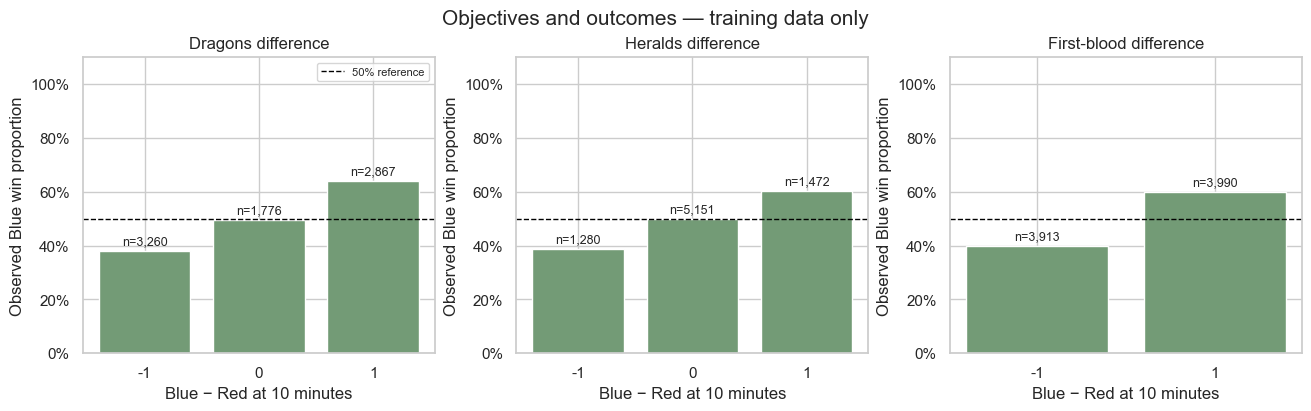

Dragons difference: Red lead 37.9% vs Blue lead 63.9% observed Blue wins.
Heralds difference: Red lead 38.6% vs Blue lead 60.3% observed Blue wins.
First-blood difference: Red lead 39.7% vs Blue lead 59.9% observed Blue wins.


In [15]:
objective_outcomes = {}
figure, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for axis, feature in zip(axes, ["dragonsDiff", "heraldsDiff", "firstBloodDiff"]):
    table = outcome_by_group(X_train[feature])
    objective_outcomes[feature] = table
    display(Markdown(f"**{feature_labels[feature]}**"))
    display(table.round(3))
    positions = np.arange(len(table))
    axis.bar(positions, table.blue_win_rate, color="#739b76")
    axis.set_xticks(positions, table.index.astype(str))
    axis.axhline(.5, color="black", linestyle="--", linewidth=1, label="50% reference")
    for position, (_, row) in enumerate(table.iterrows()):
        axis.text(position, row.blue_win_rate + .025, f"n={int(row.matches):,}", ha="center", fontsize=9)
    axis.set(title=feature_labels[feature], xlabel="Blue − Red at 10 minutes", ylabel="Observed Blue win proportion", ylim=(0, 1.1))
    axis.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
figure.suptitle("Objectives and outcomes — training data only", fontsize=15)
save_figure(figure, "06_training_win_proportions_objectives.png")
for feature, table in objective_outcomes.items():
    print(f"{feature_labels[feature]}: Red lead {table.loc[-1, 'blue_win_rate']:.1%} vs Blue lead {table.loc[1, 'blue_win_rate']:.1%} observed Blue wins.")


### 9.3 Descriptive associations with the binary target
Pearson correlation with a 0/1 response is the point-biserial correlation; Spearman correlation provides a rank-based comparison. These describe marginal associations and can miss nonlinear or joint relationships. The rankings below **do not select the features**: the 12-column domain policy was fixed before this analysis. Any supervised selection in Part B must be learned inside training cross-validation folds.


,Pearson (point-biserial),Spearman
blueGoldDiff,0.511,0.522
blueExperienceDiff,0.489,0.497
killsDiff,0.479,0.484
assistsDiff,0.385,0.388
minionsDiff,0.307,0.302
dragonsDiff,0.229,0.229
firstBloodDiff,0.201,0.201
jungleMinionsDiff,0.178,0.169
towersDestroyedDiff,0.165,0.167
heraldsDiff,0.128,0.128


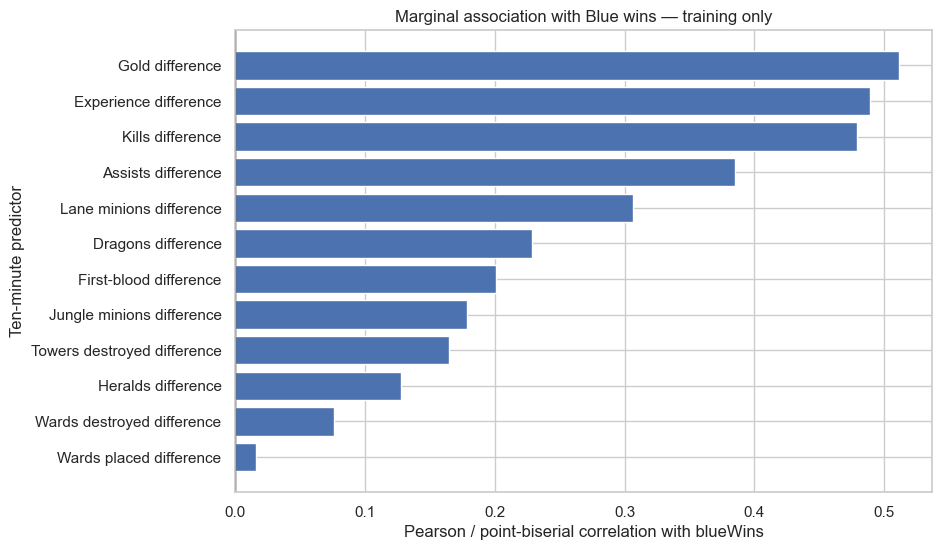

The three largest absolute Pearson associations in this training split are **blueGoldDiff** (0.511), **blueExperienceDiff** (0.489), **killsDiff** (0.479). This is descriptive evidence of overlapping early-game advantages, not a feature-selection result or model performance.

In [16]:
target_associations = pd.DataFrame({
    "Pearson (point-biserial)": X_train.corrwith(y_train, method="pearson"),
    "Spearman": X_train.corrwith(y_train, method="spearman"),
})
target_associations = target_associations.loc[target_associations.iloc[:, 0].abs().sort_values(ascending=False).index]
display(target_associations.round(3))
figure, axis = plt.subplots(figsize=(9, 6))
plot_associations = target_associations.iloc[::-1, 0]
axis.barh([feature_labels[name] for name in plot_associations.index], plot_associations.values, color="#4c72b0")
axis.axvline(0, color="black", linewidth=1)
axis.set(title="Marginal association with Blue wins — training only", xlabel="Pearson / point-biserial correlation with blueWins", ylabel="Ten-minute predictor")
save_figure(figure, "07_training_target_associations.png")
top_associations = target_associations.head(3)
display(Markdown(
    "The three largest absolute Pearson associations in this training split are "
    + ", ".join(f"**{name}** ({row.iloc[0]:.3f})" for name, row in top_associations.iterrows())
    + ". This is descriptive evidence of overlapping early-game advantages, not a feature-selection result or model performance."
))


## 10. Predictor correlation and redundancy — training data only
The heatmap excludes identifiers and the target, and uses only the 12 selected predictors so labels remain readable. We list pairs with absolute Pearson correlation at least 0.75 as a descriptive convention. The threshold does not trigger feature removal. Gold, kills, and experience measure different aspects of an advantage and can be strongly related without being exact duplicates.

High correlation means predictors may carry overlapping information. This can affect interpretation, distance-based methods, and some model estimates. Pairwise heatmaps cannot detect every multivariable identity: for example, `gold difference = Blue total − Red total` is an exact three-column relationship even when neither total has correlation 1 with the difference. We verified those identities directly in Section 3.


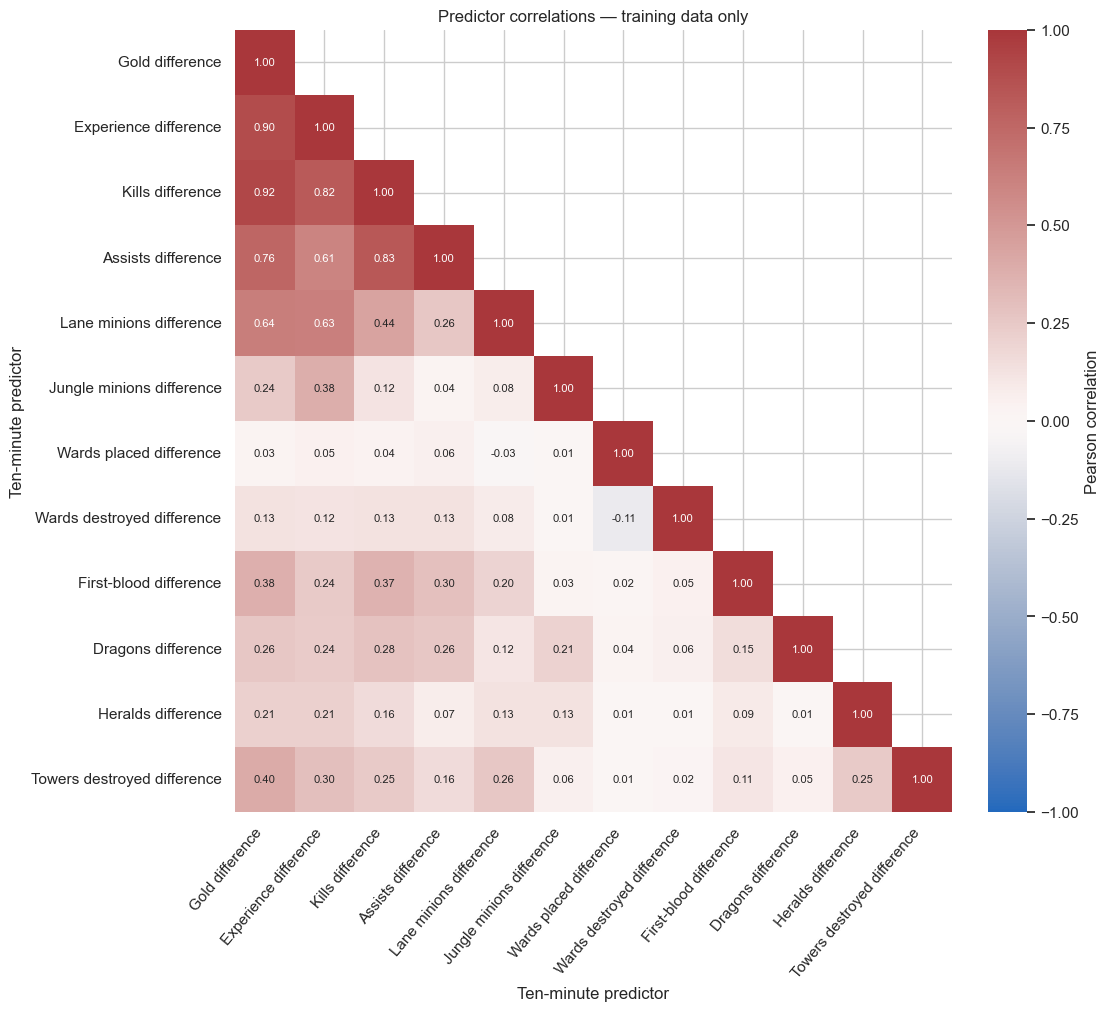

,predictor_1,predictor_2,correlation
1,blueGoldDiff,killsDiff,0.918
0,blueGoldDiff,blueExperienceDiff,0.896
4,killsDiff,assistsDiff,0.831
3,blueExperienceDiff,killsDiff,0.824
2,blueGoldDiff,assistsDiff,0.758


No additional predictors were removed after examining correlations.


In [17]:
predictor_correlation = X_train.corr()
readable_correlation = predictor_correlation.rename(index=feature_labels, columns=feature_labels)
figure, axis = plt.subplots(figsize=(11, 10), constrained_layout=True)
sns.heatmap(readable_correlation, mask=np.triu(np.ones_like(readable_correlation, dtype=bool), k=1),
            vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", annot_kws={"size": 8},
            cbar_kws={"label": "Pearson correlation"}, ax=axis)
axis.set(title="Predictor correlations — training data only", xlabel="Ten-minute predictor", ylabel="Ten-minute predictor")
axis.tick_params(axis="x", labelrotation=50)
for tick in axis.get_xticklabels():
    tick.set_ha("right")
save_figure(figure, "08_training_predictor_correlation.png")
correlated_pairs = pd.DataFrame([
    {"predictor_1": first, "predictor_2": second, "correlation": predictor_correlation.loc[first, second]}
    for position, first in enumerate(FEATURE_NAMES)
    for second in FEATURE_NAMES[position + 1:]
    if abs(predictor_correlation.loc[first, second]) >= .75
]).sort_values("correlation", ascending=False)
display(correlated_pairs.round(3))
print("No additional predictors were removed after examining correlations.")


## 11. Leakage and reproducibility validation
The following checks verify exact partition coverage, disjoint match IDs, predictor/label alignment, fixed feature order, absence of IDs and targets from X, unchanged source rows, finite predictor values, and identical repeated splits. A separate test suite checks that malformed data and changed split manifests fail visibly.

No learning operation is called anywhere in Part A. Every difference uses only two statistics from the same ten-minute snapshot. Full-source summaries are descriptive only; the test set contributes only to structural checks and the requested class-count/shape diagnostics. In Part B, scaling for KNN and SVM, any imputation, and any supervised selection must be fitted inside pipelines within training cross-validation; final evaluation uses the held-out test set once after all choices are fixed.


In [18]:
repeated = prepare_data(source_path)
for name in ["X_train", "X_test", "y_train", "y_test"]:
    left, right = getattr(prepared, name), getattr(repeated, name)
    if isinstance(left, pd.DataFrame):
        pd.testing.assert_frame_equal(left, right)
    else:
        pd.testing.assert_series_equal(left, right)

train_ids, test_ids = set(X_train.index), set(X_test.index)
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(raw_data.gameId)
assert len(X_train) + len(X_test) == len(raw_data) == 9879
assert tuple(X_train.columns) == tuple(X_test.columns) == FEATURE_NAMES
assert {TARGET, "gameId"}.isdisjoint(X_train.columns)
pd.testing.assert_index_equal(X_train.index, y_train.index)
pd.testing.assert_index_equal(X_test.index, y_test.index)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
# Feature preparation works even when final outcomes are unavailable.
pd.testing.assert_frame_equal(prepare_features(raw_data.drop(columns=TARGET)), prepare_features(raw_data))
pd.testing.assert_frame_equal(raw_data, load_data(source_path))
assert prepared.source_sha256 == ORIGINAL_SHA256
assert save_split_manifest(repeated) == manifest_path
assert len(figure_records) == 8
assert all((figure_directory / record["filename"]).is_file() for record in figure_records)
print("PASS: all notebook validation checks; all source records retained; 12 unscaled predictors.")
print("PASS: no fitted scaler, imputer, model, or supervised feature selector in Part A.")
display(pd.DataFrame(figure_records))


PASS: all notebook validation checks; all source records retained; 12 unscaled predictors.
PASS: no fitted scaler, imputer, model, or supervised feature selector in Part A.


,filename,axes
0,01_target_class_distribution.png,1
1,02_training_major_statistics_boxplots.png,6
2,03_training_feature_distributions.png,6
3,04_training_objective_distributions.png,4
4,05_training_win_proportions_gold_kills.png,2
5,06_training_win_proportions_objectives.png,3
6,07_training_target_associations.png,1
7,08_training_predictor_correlation.png,2


## 12. Handoff to Part B and student explanation
From a script or notebook running at the repository root:

```python
from src.lol_preprocessing import FEATURE_NAMES, TARGET, prepare_data, save_split_manifest

prepared = prepare_data()  # or prepare_data('/absolute/path/high_diamond_ranked_10min.csv')
save_split_manifest(prepared)  # confirms that the recorded split is unchanged
X_train, X_test = prepared.X_train, prepared.X_test
y_train, y_test = prepared.y_train, prepared.y_test
```

The four objects are ready for the later Decision Tree, KNN, and SVM comparison. Preserve the same feature order and match membership for every algorithm. Use training data only for cross-validation and any tuning. Put `StandardScaler` inside the KNN/SVM pipelines so each training fold learns its own means and standard deviations; a Decision Tree does not require scaling. Do not regenerate a favorable test split or fit preprocessing before cross-validation. This notebook deliberately contains no model training or evaluation.

**How to explain the workflow in class:**

1. **Load and inspect:** read the original CSV, check what each column represents, and show the measured dimensions and basic summaries.
2. **Check quality:** look for missing values, duplicated records, invalid flags/counts, and inconsistent team totals. We found no justified row deletion or value correction.
3. **Choose an understandable representation:** keep relative Blue-versus-Red advantages; remove identifiers and verified redundant measurements. Calculating a difference does not learn from the outcome.
4. **Reserve the test set:** use one fixed, stratified split and record its membership. The test set waits for the final comparison in Part B.
5. **Explore training data:** visualize distributions, unusual values, win proportions, and correlations. Describe associations without claiming causation or selecting predictors from the test set.
6. **Hand off unscaled data:** Part B can import the same functions. Any operation that learns from data belongs inside training-fold pipelines.

**Limits:** extreme ward counts remain unresolved without original match timelines or extraction details. The source checksum verifies this local file version, not its authenticity against a separately downloaded Kaggle copy. Random splitting does not guarantee independence across repeated players (player IDs are unavailable), or generalization across patches/time. The relative-difference representation deliberately omits absolute tempo. None of these limitations is resolved by fabricating a cleaning rule or performance result.


In [19]:
# Save a small narrative report from results actually computed above.
# It contains aggregate findings only, not source records or test predictions.
report_lines = [
    "# Part A: measured findings", "",
    f"Source: {source_path.name}; SHA-256 `{prepared.source_sha256}`.",
    f"Observed source shape: {len(raw_data):,} matches, {raw_data.shape[1]} columns.",
    "No observations removed or values corrected.", "",
    f"Missing values: {quality_report['total_missing']}; identical duplicate rows: {quality_report['duplicate_rows']}; repeated gameId values: {quality_report['duplicate_game_ids']}.",
    "All numeric/binary/count/level and 13 arithmetic consistency checks passed.",
    f"Red wins: {int(class_counts[0]):,} ({class_counts[0]/len(raw_data):.3%}); Blue wins: {int(class_counts[1]):,} ({class_counts[1]/len(raw_data):.3%}).", "",
    f"Training: {len(X_train):,} × {X_train.shape[1]} predictors; labels {y_train.shape}. Red {int((y_train==0).sum()):,}, Blue {int((y_train==1).sum()):,}.",
    f"Test: {len(X_test):,} × {X_test.shape[1]} predictors; labels {y_test.shape}. Red {int((y_test==0).sum()):,}, Blue {int((y_test==1).sum()):,}.",
    "80/20 stratified split, random_state=42, gameId ascending before splitting. No scaler, imputer, selector, or model fitted.", "",
    "Retained original predictors: blueGoldDiff, blueExperienceDiff.",
    "Engineered predictors: " + ", ".join(DIFFERENCE_SOURCES) + ". All are Blue minus Red.",
    "Excluded original columns and individual reasons are listed in the notebook and feature_decisions().", "",
    "Training-only Pearson associations (descriptive; not feature selection):",
]
for name, row in target_associations.iterrows():
    report_lines.append(f"- {name}: {row.iloc[0]:.3f}")
report_lines += ["", "Training-only predictor pairs with absolute Pearson correlation ≥ 0.75:"]
for row in correlated_pairs.itertuples(index=False):
    report_lines.append(f"- {row.predictor_1} / {row.predictor_2}: {row.correlation:.3f}")
report_lines += ["", "Training-only extreme-value summaries (min to max; IQR flag counts are descriptive):"]
for name, row in outlier_summary.iterrows():
    report_lines.append(f"- {name}: {row['min']:g} to {row['max']:g}; {int(row.IQR_flagged_count)} flagged.")
report_lines += ["", f"Ward counts reach {ward_maximum} in training. Hundreds of wards at ten minutes are suspicious; the CSV cannot establish whether they are valid or extraction artifacts. All retained.",
    "Gold, combat, experience and minion extremes may be legitimate; an IQR flag is not evidence of an error. No outlier filtering, clipping or replacement performed.",
    "All eight figures use training data except the explicitly labeled full-source class-distribution figure.",
    "Notebook assertions passed: source count, predictor exclusion, finite data, disjoint and complete partition, alignment, repeated split, feature transformation without the target, source unchanged and figure labels/files.",
    "The automated test suite is separate; see README.md for its command. No model training, tuning, or evaluation performed.", ""]
report_path = repository_root / "reports/part_a_findings.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Saved:", report_path.relative_to(repository_root))


Saved: reports/part_a_findings.md
